# 03 - Regressione logistica

**Progetto:** Credit Risk Scorecard - *Give Me Some Credit*

Costruiamo un modello di regressione logistica per stimare la probabilità di insolvenza
(`SeriousDlqin2yrs`). Passi del notebook:

1. Caricamento del dataset pulito
2. Controllo della multicollinearità (VIF) prima di interpretare qualunque coefficiente
3. Split train/test (80/20) stratificato sul target
4. Stima del modello con **statsmodels** (p-value e intervalli di confidenza sui coefficienti,
   non solo predizioni)
5. Interpretazione tramite **odds ratio** con IC 95%
6. Valutazione: pseudo R² di McFadden, matrice di confusione, precision/recall/F1, curva ROC e AUC
7. Applicazione del modello a tutto il dataset e salvataggio delle probabilità di default (PD) per
   il notebook di Expected Loss
8. Confronto con quanto osservato nei test d'ipotesi del notebook `02_analisi_statistica`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                              f1_score, accuracy_score, roc_auc_score, roc_curve)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
RANDOM_SEED = 42

COLOR_GOOD = '#0ca30c'
COLOR_CRITICAL = '#d03b3b'
COLOR_SEQ = '#2a78d6'
GRID_COLOR = '#e1e0d9'
TEXT_COLOR = '#0b0b0b'
MUTED_COLOR = '#898781'

plt.rcParams.update({
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID_COLOR,
    'axes.grid': True,
    'grid.color': GRID_COLOR,
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': MUTED_COLOR,
    'ytick.color': MUTED_COLOR,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Caricamento dataset pulito

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
CLEAN_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cs-training-clean.csv'

df = pd.read_csv(CLEAN_PATH, index_col=0)
TARGET = 'SeriousDlqin2yrs'

# Le 3 colonne indicatore create nel notebook 01_eda entrano tra i predittori:
# preservano segnale (missingness informativa, record con codici sentinella).
CANDIDATE_FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents',
    'MonthlyIncome_mancante',
    'NumberOfDependents_mancante',
    'flag_delinquenza_anomala',
]

print(f"Righe: {len(df):,}  |  Predittori candidati: {len(CANDIDATE_FEATURES)}")

Righe: 149,999  |  Predittori candidati: 13


## 2. Multicollinearità: Variance Inflation Factor (VIF)

Le tre colonne sui ritardi di pagamento (`NumberOfTime30-59DaysPastDueNotWorse`,
`NumberOfTime60-89DaysPastDueNotWorse`, `NumberOfTimes90DaysLate`) misurano comportamenti simili
(essere in ritardo) e sono ragionevolmente candidate a essere correlate tra loro. Verifichiamo
prima la correlazione grezza, poi il VIF (che considera la relazione di ciascuna variabile con
**tutte** le altre insieme, non solo a coppie: è la misura corretta per capire se i coefficienti
della regressione saranno stabili).

In [3]:
delinq_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
]
print("Correlazione tra le 3 colonne di ritardo:")
df[delinq_cols].corr().round(3)

Correlazione tra le 3 colonne di ritardo:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.000,0.639,0.603
NumberOfTime60-89DaysPastDueNotWorse,0.639,1.000,0.770
NumberOfTimes90DaysLate,0.603,0.770,1.000


In [4]:
X_vif = sm.add_constant(df[CANDIDATE_FEATURES])
vif_df = pd.DataFrame({
    'variabile': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
})
vif_df = vif_df[vif_df['variabile'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
vif_df.round(2)

,variabile,VIF
0,flag_delinquenza_anomala,4.48
1,NumberOfTimes90DaysLate,3.68
2,NumberOfTime60-89DaysPastDueNotWorse,3.51
3,MonthlyIncome_mancante,2.19
4,DebtRatio,1.98
5,NumberOfTime30-59DaysPastDueNotWorse,1.89
6,NumberOfOpenCreditLinesAndLoans,1.34
7,NumberRealEstateLoansOrLines,1.33
8,RevolvingUtilizationOfUnsecuredLines,1.23
9,age,1.17


**Lettura.** La correlazione grezza tra le tre colonne di ritardo è effettivamente moderata-alta
(0,60-0,77), ma il **VIF non supera mai 5** (soglia convenzionale di attenzione; 10 quella di
allarme) — il valore più alto è `flag_delinquenza_anomala` (4,48), seguito dalle colonne di
ritardo stesse (3,5-3,7). La multicollinearità grezza tra queste variabili, quindi, **non si
traduce in un problema di VIF**: le altre variabili nel modello (in particolare le tre colonne di
ritardo prese insieme) non spiegano una quota della varianza di nessuna di esse tale da rendere i
coefficienti instabili. Non le accorpiamo né le rimuoviamo: manteniamo la distinzione per gravità
del ritardo, che ha valore informativo proprio (un ritardo di 90+ giorni non equivale a uno di
30-59). Continuiamo comunque a tenerle d'occhio nel passo successivo, perché — come vedremo — il
problema reale è altrove.

## 3. Split train/test (80/20, stratificato)

Con un tasso di default del 6,68%, uno split casuale non stratificato potrebbe produrre per caso
un test set con una proporzione di insolventi sensibilmente diversa dal training set, rendendo la
valutazione meno affidabile. La stratificazione su `SeriousDlqin2yrs` mantiene la stessa
proporzione in entrambi i set.

In [5]:
X = df[CANDIDATE_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)

print(f"Train: {len(X_train):,} righe, tasso default {y_train.mean() * 100:.2f}%")
print(f"Test:  {len(X_test):,} righe, tasso default {y_test.mean() * 100:.2f}%")

Train: 119,999 righe, tasso default 6.68%
Test:  30,000 righe, tasso default 6.68%


## 4. Modello di regressione logistica (statsmodels)

Stimiamo prima il modello con **tutti** i predittori candidati.

In [6]:
X_train_c = sm.add_constant(X_train)
model_v1 = sm.Logit(y_train, X_train_c)
result_v1 = model_v1.fit(disp=0)
result_v1.params.sort_values()

flag_delinquenza_anomala               -21.645801
const                                   -3.476554
NumberOfDependents_mancante             -0.165161
age                                     -0.016515
DebtRatio                               -0.000133
MonthlyIncome                           -0.000024
NumberOfOpenCreditLinesAndLoans          0.028851
NumberOfDependents                       0.044629
NumberRealEstateLoansOrLines             0.104049
MonthlyIncome_mancante                   0.197556
NumberOfTime30-59DaysPastDueNotWorse     0.423544
NumberOfTime60-89DaysPastDueNotWorse     0.631466
NumberOfTimes90DaysLate                  0.668577
RevolvingUtilizationOfUnsecuredLines     2.044265
dtype: float64

**Problema.** Il coefficiente di `flag_delinquenza_anomala` è **-21,6** (odds ratio ≈ 4×10⁻¹⁰,
praticamente zero). Letto come "effetto del flag a parità delle altre variabili" non ha senso: le
righe con flag = 1 hanno un tasso di insolvenza del 54,6%, molto *più alto* della media. Prima di
interpretarlo verifichiamo come il flag si relaziona alle tre colonne di ritardo.

In [7]:
flagged = df[df['flag_delinquenza_anomala'] == 1]
print("Combinazioni uniche di (30-59, 60-89, 90+) tra le righe con flag=1:")
print(flagged[delinq_cols].drop_duplicates())

combo = flagged[delinq_cols].iloc[0]
mask_same_combo = (df[delinq_cols] == combo).all(axis=1)
print(f"\nRighe con questa combinazione esatta: {mask_same_combo.sum()}")
print(f"...di cui con flag_delinquenza_anomala = 0: {(mask_same_combo & (df['flag_delinquenza_anomala'] == 0)).sum()}")

Combinazioni uniche di (30-59, 60-89, 90+) tra le righe con flag=1:
      NumberOfTime30-59DaysPastDueNotWorse  NumberOfTime60-89DaysPastDueNotWorse  NumberOfTimes90DaysLate
id                                                                                                       
1734                                    13                                    11                       17

Righe con questa combinazione esatta: 269
...di cui con flag_delinquenza_anomala = 0: 0


**Diagnosi.** Tutte le 269 righe con `flag_delinquenza_anomala = 1` condividono **esattamente** la
stessa combinazione di valori nelle tre colonne di ritardo (13, 11, 17), perché nel notebook
`01_eda` le abbiamo *cappate* tutte allo stesso valore massimo per ciascuna colonna, e nessuna riga
con flag = 0 ha questa combinazione. Il flag quindi **non varia mai da solo**: è sempre accompagnato
da quei tre valori estremi.

Non si tratta di separazione: tra le 269 righe ci sono sia insolventi sia non insolventi (54,6% di
default), quindi il flag non predice perfettamente l'esito. Il coefficiente di -21,6 è una
**correzione**: con i coefficienti per unità di questo modello (0,42, 0,63 e 0,67), i ritardi
cappati aggiungono circa 0,42 × 13 + 0,63 × 11 + 0,67 × 17 ≈ +23,8 punti di logit, e il flag ne
toglie 21,6. L'effetto netto, circa +2,2, è coerente con il 54,6% di default osservato in quelle
righe. La dipendenza tra flag e ritardi è deterministica ma non lineare: per questo il VIF del flag
(4,48, il più alto della tabella precedente) resta sotto la soglia di allarme.

**Decisione:** escludiamo `flag_delinquenza_anomala` dal modello di regressione (resta comunque nel
dataset pulito), perché il suo coefficiente non si può leggere come effetto a parità delle altre
variabili. Il prezzo è che, senza questa correzione, il modello logistico **sovrastima la PD** di
quelle 269 righe, spinte verso l'alto dai ritardi cappati. Le PD usate per Expected Loss e what-if
vengono dal modello XGBoost (notebook `04`).

In [8]:
FEATURES = [c for c in CANDIDATE_FEATURES if c != 'flag_delinquenza_anomala']

X_train, X_test = X_train[FEATURES], X_test[FEATURES]
X_train_c = sm.add_constant(X_train)
X_test_c = sm.add_constant(X_test)

model = sm.Logit(y_train, X_train_c)
result = model.fit(disp=0)
print(result.summary())

                           Logit Regression Results                           
Dep. Variable:       SeriousDlqin2yrs   No. Observations:               119999
Model:                          Logit   Df Residuals:                   119986
Method:                           MLE   Df Model:                           12
Date:                Sat, 12 Sep 2026   Pseudo R-squ.:                  0.1929
Time:                        20:53:27   Log-Likelihood:                -23767.
converged:                       True   LL-Null:                       -29447.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
const                                   -3.5007      0.061    -57.280      0.000      -3.620      -3.381
RevolvingUtilizationOfUnsecuredLines     2.3204      

Tutti i coefficienti sono ora di ordine di grandezza plausibile e leggibili come effetto a
parità delle altre variabili: procediamo con questo modello.

## 5. Odds ratio e intervalli di confidenza al 95%

L'odds ratio (esponenziale del coefficiente) si legge come: *"un aumento di un'unità nella
variabile X moltiplica gli odds di insolvenza per OR, a parità delle altre variabili"* — OR > 1
aumenta il rischio, OR < 1 lo riduce, OR ≈ 1 non ha effetto.

In [9]:
conf = result.conf_int()
conf.columns = ['ci95_low', 'ci95_high']

or_table = pd.DataFrame({
    'coef': result.params,
    'p_value': result.pvalues,
    'OR': np.exp(result.params),
    'OR_ci95_low': np.exp(conf['ci95_low']),
    'OR_ci95_high': np.exp(conf['ci95_high']),
}).drop(index='const')

or_table.sort_values('p_value').round(4)

,coef,p_value,OR,OR_ci95_low,OR_ci95_high
RevolvingUtilizationOfUnsecuredLines,2.3204,0.0000,10.1793,9.4547,10.9594
NumberOfTime30-59DaysPastDueNotWorse,0.3422,0.0000,1.4081,1.3747,1.4423
NumberOfTimes90DaysLate,0.3077,0.0000,1.3603,1.3188,1.4031
age,-0.0150,0.0000,0.9851,0.9832,0.9871
NumberOfOpenCreditLinesAndLoans,0.0301,0.0000,1.0306,1.0249,1.0363
NumberOfTime60-89DaysPastDueNotWorse,0.2094,0.0000,1.2329,1.1761,1.2925
MonthlyIncome,-0.0000,0.0000,1.0000,1.0000,1.0000
NumberRealEstateLoansOrLines,0.0848,0.0000,1.0885,1.0635,1.1141
NumberOfDependents,0.0626,0.0000,1.0646,1.0422,1.0874
DebtRatio,-0.0001,0.0000,0.9999,0.9998,0.9999


## 6. Valutazione del modello

### Pseudo R² di McFadden

In [10]:
print(f"Pseudo R² di McFadden: {result.prsquared:.4f}")
print(f"Log-likelihood modello: {result.llf:.1f}  |  Log-likelihood solo intercetta: {result.llnull:.1f}")

Pseudo R² di McFadden: 0.1929
Log-likelihood modello: -23767.3  |  Log-likelihood solo intercetta: -29446.9


McFadden suggerisce che valori tra 0,2 e 0,4 indicano un buon adattamento (è una scala diversa
dall'R² lineare, valori "piccoli" in valore assoluto sono normali). Il nostro modello, circa 0,19,
è nella fascia alta accettabile per un problema di scoring creditizio con una singola fonte di dati
tabellare.

### Matrice di confusione, precision, recall, F1 (test set)

**Perché non basta l'accuracy:** con un tasso di default del 6,68%, un modello che predicesse
*sempre* "nessun default" avrebbe comunque un'accuracy del 93,3% pur essendo completamente inutile
(non identifica mai un cliente a rischio). L'accuracy da sola premia la classe maggioritaria e
nasconde la capacità reale del modello di individuare gli insolventi: per questo servono
precision, recall e F1, calcolate specificamente sulla classe di interesse (insolventi = 1).

In [11]:
proba_test = result.predict(X_test_c)

baseline_accuracy = 1 - y_test.mean()
print(f"Accuracy di un modello banale che predice sempre 'non insolvente': {baseline_accuracy:.4f}")

for thr in [0.5, y_train.mean()]:
    pred = (proba_test >= thr).astype(int)
    print(f"\n--- soglia = {thr:.4f} ---")
    print(f"Accuracy:  {accuracy_score(y_test, pred):.4f}")
    print(f"Precision: {precision_score(y_test, pred):.4f}")
    print(f"Recall:    {recall_score(y_test, pred):.4f}")
    print(f"F1:        {f1_score(y_test, pred):.4f}")

Accuracy di un modello banale che predice sempre 'non insolvente': 0.9332

--- soglia = 0.5000 ---
Accuracy:  0.9355
Precision: 0.6254
Recall:    0.0883
F1:        0.1547

--- soglia = 0.0668 ---
Accuracy:  0.7618
Precision: 0.1857
Recall:    0.7576
F1:        0.2983


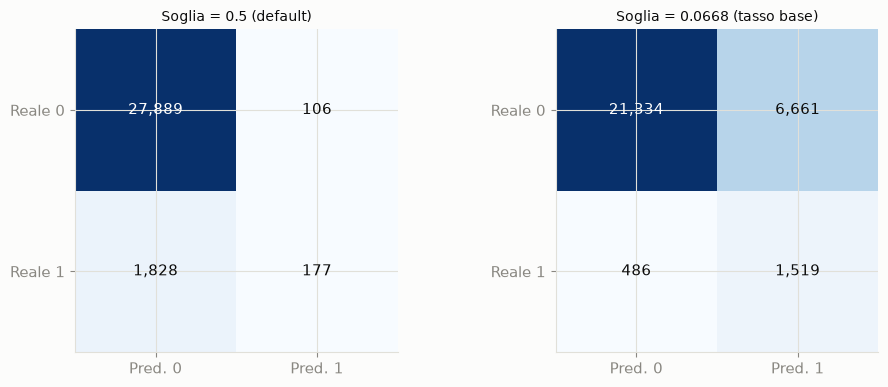

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
thresholds_to_plot = [0.5, y_train.mean()]
titles = ['Soglia = 0.5 (default)', f'Soglia = {y_train.mean():.4f} (tasso base)']

for ax, thr, title in zip(axes, thresholds_to_plot, titles):
    pred = (proba_test >= thr).astype(int)
    cm = confusion_matrix(y_test, pred)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred. 0', 'Pred. 1']); ax.set_yticklabels(['Reale 0', 'Reale 1'])
    ax.set_title(title, fontsize=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else TEXT_COLOR, fontsize=11)

plt.tight_layout()
plt.show()

**Il confronto tra le due soglie mostra esattamente il problema:** a soglia 0,5 l'accuracy è alta
(93,6%, appena sopra il banale 93,3%) ma il recall è solo 8-9% — il modello lascia passare la
stragrande maggioranza degli insolventi reali. Abbassando la soglia al tasso di default osservato
(6,68%), il recall sale a oltre il 75% (si individuano molti più clienti a rischio) ma l'accuracy
**scende sotto il baseline banale** (76%), perché il modello ora segnala anche molti clienti che
poi non andranno in default. Nessuna delle due soglie è "quella giusta" in astratto: la scelta
dipende dal costo relativo di un falso negativo (mancato allarme su un cliente che poi non paga)
rispetto a un falso positivo (rifiutare o rivedere un cliente che invece avrebbe pagato) — un
compromesso che affronteremo concretamente nel notebook `06_expected_loss`.

### Curva ROC e AUC

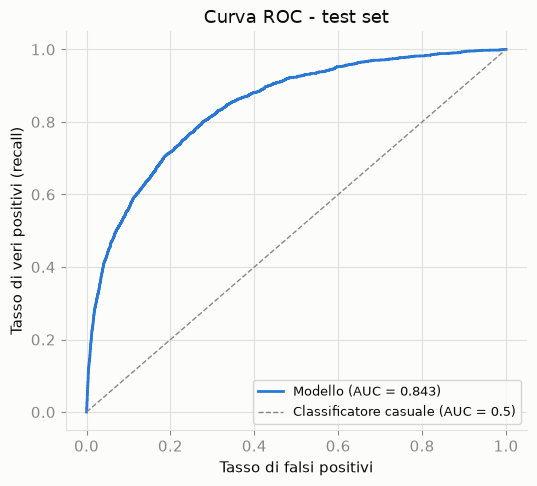

AUC: 0.8431


In [13]:
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc = roc_auc_score(y_test, proba_test)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color=COLOR_SEQ, linewidth=2, label=f'Modello (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], color=MUTED_COLOR, linestyle='--', linewidth=1, label='Classificatore casuale (AUC = 0.5)')
ax.set_xlabel('Tasso di falsi positivi')
ax.set_ylabel('Tasso di veri positivi (recall)')
ax.set_title('Curva ROC - test set')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

print(f"AUC: {auc:.4f}")

A differenza di accuracy/precision/recall (che dipendono dalla soglia scelta), l'AUC misura la
capacità del modello di **ordinare correttamente** i clienti per rischio a qualunque soglia: un
AUC di 0,84 indica che, presa una coppia casuale (un insolvente, un non insolvente), il modello
assegna una probabilità di default più alta all'insolvente nell'84% dei casi circa — una buona
capacità discriminante per un modello lineare con queste variabili.

## 7. Applicazione a tutto il dataset e salvataggio delle PD

Usiamo il modello già stimato (allenato sul solo training set) per calcolare la probabilità di
default (PD) su **tutti** i 149.999 clienti. Le PD sulle righe di training sono stime "in-sample"
(il modello le ha già viste in fase di stima); quelle sulle righe di test sono le stesse già
valutate onestamente sopra. Il file va usato nel notebook `06_expected_loss` per calcolare la
perdita attesa, non come nuova validazione delle prestazioni del modello.

In [14]:
X_full_c = sm.add_constant(df[FEATURES], has_constant='add')
pd_full = result.predict(X_full_c)

output = pd.DataFrame({
    'CustomerID': df.index,
    'PD': pd_full.values,
    'SeriousDlqin2yrs': df[TARGET].values,
})

print(f"PD media stimata: {output['PD'].mean():.4f}  |  tasso di default osservato: {df[TARGET].mean():.4f}")

PD media stimata: 0.0670  |  tasso di default osservato: 0.0668


In [15]:
OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'probabilita_insolvenza.csv'
output.to_csv(OUTPUT_PATH, index=False)
print(f"Salvato: {OUTPUT_PATH.relative_to(PROJECT_ROOT).as_posix()}  ({len(output):,} righe)")

Salvato: data/processed/probabilita_insolvenza.csv  (149,999 righe)


## 8. Quali variabili sono più influenti?

Gli odds ratio "per unità" della Sezione 5 non sono direttamente confrontabili tra loro: un'unità
significa cose molto diverse a seconda della variabile (1 dollaro di reddito, 1 anno di età, 1
punto intero di utilizzo revolving). Per confrontare l'influenza pratica delle variabili continue
usiamo l'odds ratio scalato per l'**IQR** (differenza tra 75° e 25° percentile, calcolata sul
training set): rappresenta "quanto cambia il rischio passando da un valore tipicamente basso a uno
tipicamente alto" della variabile. Per le tre colonne di ritardo l'IQR è **zero** (oltre il 75% dei
clienti non ha mai avuto ritardi, quindi Q1 = Q3 = 0): per queste tre riportiamo invece l'odds
ratio "per unità" già visto in Sezione 5, che resta comunque interpretabile (un ritardo aggiuntivo
alla volta). Per le due variabili binarie (flag di missing) l'odds ratio 0→1 è già la scala
naturale.

In [16]:
BINARY_FLAGS = ['MonthlyIncome_mancante', 'NumberOfDependents_mancante']
ZERO_INFLATED = delinq_cols  # IQR = 0 per queste colonne

rows = []
for var in FEATURES:
    coef = result.params[var]
    if var in BINARY_FLAGS:
        tipo, ampiezza, or_scaled = '0 -> 1 (flag)', 1.0, np.exp(coef)
    elif var in ZERO_INFLATED:
        tipo, ampiezza, or_scaled = 'per unità (IQR=0)', 1.0, np.exp(coef)
    else:
        iqr = X_train[var].quantile(0.75) - X_train[var].quantile(0.25)
        tipo, ampiezza, or_scaled = 'IQR (Q3-Q1)', iqr, np.exp(coef * iqr)
    rows.append({
        'variabile': var, 'tipo_confronto': tipo, 'ampiezza': ampiezza,
        'OR_scalato': or_scaled, 'p_value': result.pvalues[var],
    })

comparison_df = pd.DataFrame(rows).sort_values(
    by='OR_scalato', key=lambda s: (s - 1).abs(), ascending=False
).set_index('variabile')
comparison_df.round(4)

,tipo_confronto,ampiezza,OR_scalato,p_value
variabile,,,,
RevolvingUtilizationOfUnsecuredLines,IQR (Q3-Q1),0.5285,3.4084,0.0000
NumberOfTime30-59DaysPastDueNotWorse,per unità (IQR=0),1.0000,1.4081,0.0000
NumberOfTimes90DaysLate,per unità (IQR=0),1.0000,1.3603,0.0000
age,IQR (Q3-Q1),22.0000,0.7189,0.0000
NumberOfDependents_mancante,0 -> 1 (flag),1.0000,0.7586,0.0104
NumberOfTime60-89DaysPastDueNotWorse,per unità (IQR=0),1.0000,1.2329,0.0000
NumberOfOpenCreditLinesAndLoans,IQR (Q3-Q1),6.0000,1.1982,0.0000
NumberRealEstateLoansOrLines,IQR (Q3-Q1),2.0000,1.1849,0.0000
MonthlyIncome_mancante,0 -> 1 (flag),1.0000,1.1738,0.0015


**Le variabili più influenti, in ordine:**

1. **`RevolvingUtilizationOfUnsecuredLines`** — di gran lunga la più influente: passare dal 25° al
   75° percentile di utilizzo (+0,53 punti) **triplica** circa gli odds di insolvenza. Coerente al
   100% con il notebook `02_analisi_statistica`, dove questa variabile aveva il solo effect size
   "grande" (r = 0,556) tra le cinque testate.
2. **`age`** — seconda per influenza: dal 25° al 75° percentile (+22 anni) gli odds si riducono di
   circa il 28% (OR ≈ 0,72). Anche qui coerente con il notebook precedente (Cohen's d = -0,465,
   "piccolo" ma vicino alla soglia "medio").
3. **Le tre colonne di ritardo pagamenti** — ogni ritardo aggiuntivo nella rispettiva fascia
   aumenta gli odds del 23-41%; con più ritardi accumulati l'effetto si moltiplica (es. 3 ritardi
   30-59 giorni: OR ≈ 1,41³ ≈ 2,8).
4. Le restanti variabili (`MonthlyIncome`, `NumberOfOpenCreditLinesAndLoans`,
   `NumberRealEstateLoansOrLines`, `NumberOfDependents`, `DebtRatio`,
   `MonthlyIncome_mancante`) hanno odds ratio scalati compresi tra 0,91 e 1,20: un contributo reale
   ma modesto preso singolarmente. `NumberOfDependents_mancante` (OR ≈ 0,76, riduzione di circa il
   24%) si discosta un po' di più dal gruppo, ma ha un intervallo di confidenza ampio (0,61-0,94,
   coerente con l'interessare solo il 2,6% delle righe) e un peso comunque secondario rispetto alle
   prime due variabili.

**Confronto con il notebook `02_analisi_statistica`: due differenze interessanti, non contraddizioni.**

- **`DebtRatio`** ha coefficiente **negativo** nel modello multivariato (OR ≈ 1,000, sostanzialmente
  nullo), mentre nel test univariato del notebook precedente la mediana era **più alta** tra gli
  insolventi (effect size comunque trascurabile, r = 0,048). Non è un'incoerenza: il test
  univariato confronta i due gruppi ignorando le altre variabili, mentre il coefficiente
  multivariato misura l'effetto "a parità" di reddito, utilizzo, ritardi, ecc. Una volta tenuto
  conto delle altre variabili (in particolare `MonthlyIncome`, con cui `DebtRatio` interagisce
  fortemente per costruzione, si veda `01_eda`), il contributo indipendente di `DebtRatio` si
  annulla quasi del tutto. In entrambi i notebook la conclusione pratica coincide: **effetto
  trascurabile**.
- **`NumberOfOpenCreditLinesAndLoans`** aveva mostrato una mediana leggermente **più bassa** tra
  gli insolventi nel notebook precedente (effect size trascurabile, r = -0,089), ma qui il
  coefficiente multivariato è **positivo** (OR > 1: più linee di credito aperte, a parità di tutto
  il resto, aumentano leggermente gli odds). Anche questo è plausibile: guardata da sola questa
  variabile si confonde con l'effetto di clienti "solidi" che hanno sia più linee di credito sia
  redditi più alti; a parità di reddito e utilizzo, avere molte linee aperte diventa invece un
  segnale (debole) di maggiore esposizione. Anche qui, in entrambi i casi l'effetto resta piccolo.

**In sintesi:** le due variabili che il notebook `02` aveva già segnalato come le più separate tra
i gruppi — `RevolvingUtilizationOfUnsecuredLines` e `age` — restano anche le più influenti nel
modello multivariato. Le tre colonne di ritardo pagamenti, non testate singolarmente nel notebook
precedente, emergono qui come un blocco di predittori forte quanto l'utilizzo revolving quando si
considerano ritardi ripetuti. `DebtRatio` e `NumberOfOpenCreditLinesAndLoans` confermano il loro
ruolo marginale, con la sola differenza — degna di nota ma non preoccupante — che il segno
dell'effetto può cambiare passando da un confronto univariato a uno che controlla per le altre
variabili.